Study the objectives for different attack objectives, L2 and cos distance.

In [60]:
import sys
import os

# Manually specify the path to your project folder
project_path = os.path.abspath('..')  # Or provide the full path if needed
sys.path.append(project_path)

# Now you can import from the sibling folder
from utilities import *
from helper import *

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as T

import torchvision.datasets as datasets
from torch.utils.data import DataLoader
from models import *
import random
from collections import Counter
from collections import OrderedDict
import seaborn as sns
from copy import deepcopy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from collections import Counter

cos = nn.CosineSimilarity(dim=0, eps=1e-9) 
device = "cuda"

# study 1 model's training with the new loss function with dist limits

# adjustable parameters
# alpha_d = 100 # IID
iters = 40
learning_rate = 0.001

global attack 
attack = "MobileNetV2_32" #"backdoor", "tlp", "ut"
model_name = "VGG13_32" # "resnet8", "ConvNet"
num_classes = 10
pooled_num = 20
dataset = "cifar10" # "cifar10", "fmnist"

In [ ]:
# Define transformation (convert images to tensors and normalize)
transform_img = T.Compose([
    T.ToTensor(),  # Convert image to tensor
    T.Normalize((0.5,), (0.5,))  # Normalize the image with mean and std
])

if dataset == "mnist":
    train_data = datasets.MNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.MNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "fmnist":
    train_data = datasets.FashionMNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.FashionMNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "cifar10":
    train_data = datasets.CIFAR10(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.CIFAR10(root=f'{project_path}/data', train=False, download=True, transform=transform_img)

Files already downloaded and verified


In [ ]:
# Create DataLoader for batch processing
fl_data_dict, labels_per_client_dict, label_count_per_client_dict =\
    create_data_fl_clients(client_num=100,
                           noniid_type="dirichlet",
                           label_skew_alpha =None,
                           p_degree=None,
                           dirichlet_alpha=100,
                           fl_train=train_data,
                           fl_class_num=10)

# Combine datasets from clients 0 to 9
combined_dataset = ConcatDataset([fl_data_dict[i] for i in range(pooled_num)])
  
# Create a DataLoader for the combined dataset
train_loader = DataLoader(combined_dataset, batch_size=32, shuffle=True, num_workers=0)

In [ ]:
# Collect all labels from the combined dataset
all_labels = [label for _, label in combined_dataset]

# Count the occurrences of each label
label_counts = Counter(all_labels)

# Optionally, print the counts in order
for label in range(10):  # assuming 10 classes
    print(f"Label {label}: {label_counts[label]}")

Label 0: 997
Label 1: 1004
Label 2: 1024
Label 3: 1004
Label 4: 1014
Label 5: 1032
Label 6: 977
Label 7: 1023
Label 8: 1009
Label 9: 981


In [ ]:
model_class = get_model(model_name)    
model_fn = partial(model_class, num_classes=num_classes)
# model0
model0 = model_fn().to(device)
model0_sd = deepcopy(model0.state_dict())
optimizer0 = optim.SGD(model0.parameters(), lr=learning_rate)
c_criterion0 = nn.CrossEntropyLoss()

# modelt 
modelt = model_fn().to(device)
modelt.load_state_dict(model0_sd)
optimizer1 = optim.SGD(modelt.parameters(), lr=learning_rate)
c_criterion1 = nn.CrossEntropyLoss()

In [ ]:
# Helper: clone model parameters
def clone_model_params(model):
    return {name: param.detach().clone() for name, param in model.state_dict().items()}

# Helper: compute model update
def compute_model_update(current_state, previous_state):
    return {name: current_state[name] - previous_state[name] for name in current_state}

In [ ]:
# Initialize
model_updates = {}  # store updates like {1: g_1, 2: g_2, ...}
prev_model_state = clone_model_params(model0)
accuracy_list =[]

# Normal training to converge
for iter in range(iters):
    train_c_model(train_loader, model0, c_criterion0, optimizer0, attack_method='none', client_id=0,
                  malicious_client_ids=[], optimizer_poison=None, dba_poisoning_per_batch=0.2, device=device)

    # Compute model update
    current_model_state = clone_model_params(model0)
    model_updates[iter + 1] = compute_model_update(current_model_state, prev_model_state)
    prev_model_state = current_model_state  # update for next iteration

    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(model0, c_criterion0, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
    accuracy_list.append(accuracy)
    print(f"iter:{iter}, accuracy:{accuracy}")

iter:0, accuracy:0.1748
iter:1, accuracy:0.2454
iter:2, accuracy:0.2793
iter:3, accuracy:0.294
iter:4, accuracy:0.3081
iter:5, accuracy:0.3077
iter:6, accuracy:0.3258
iter:7, accuracy:0.3446
iter:8, accuracy:0.3588
iter:9, accuracy:0.383
iter:10, accuracy:0.404
iter:11, accuracy:0.418
iter:12, accuracy:0.4236
iter:13, accuracy:0.4538
iter:14, accuracy:0.4582
iter:15, accuracy:0.4423
iter:16, accuracy:0.4734
iter:17, accuracy:0.5105
iter:18, accuracy:0.5216
iter:19, accuracy:0.5381
iter:20, accuracy:0.4719
iter:21, accuracy:0.5133
iter:22, accuracy:0.559
iter:23, accuracy:0.568
iter:24, accuracy:0.5465
iter:25, accuracy:0.5751
iter:26, accuracy:0.5673
iter:27, accuracy:0.5395
iter:28, accuracy:0.5501
iter:29, accuracy:0.5614
iter:30, accuracy:0.5684
iter:31, accuracy:0.5198
iter:32, accuracy:0.5571
iter:33, accuracy:0.5781
iter:34, accuracy:0.6068
iter:35, accuracy:0.5746
iter:36, accuracy:0.5798
iter:37, accuracy:0.5832
iter:38, accuracy:0.4032
iter:39, accuracy:0.5987


In [ ]:
# Flatten a model update (dict of tensors) into a single 1D tensor
def flatten_update(update_dict):
    return torch.cat([v.view(-1) for v in update_dict.values()])

# Step 1: Compute flattened updates
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 1: L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 2: Cosine distance matrix (1 - cosine similarity)
cos_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
for i in range(len(flattened_updates)):
    for j in range(len(flattened_updates)):
        cos_sim = F.cosine_similarity(flattened_updates[i], flattened_updates[j], dim=0).item()
        cos_diff_matrix[i, j] = 1 - cos_sim

# Step 3: L2 distance matrix
l2_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
for i in range(len(flattened_updates)):
    for j in range(len(flattened_updates)):
        l2_diff = torch.norm(flattened_updates[i] - flattened_updates[j]).item()
        l2_diff_matrix[i, j] = l2_diff

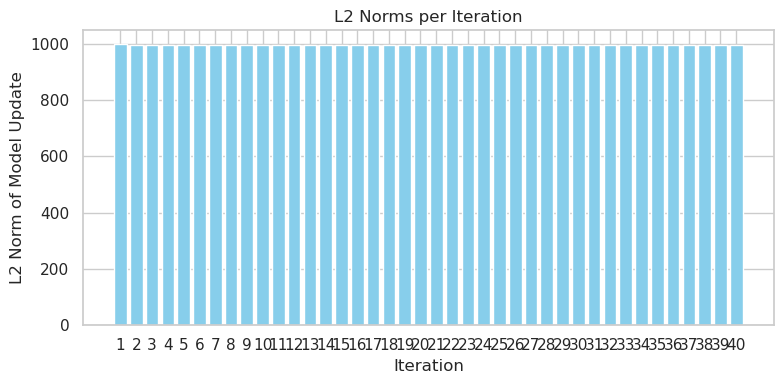

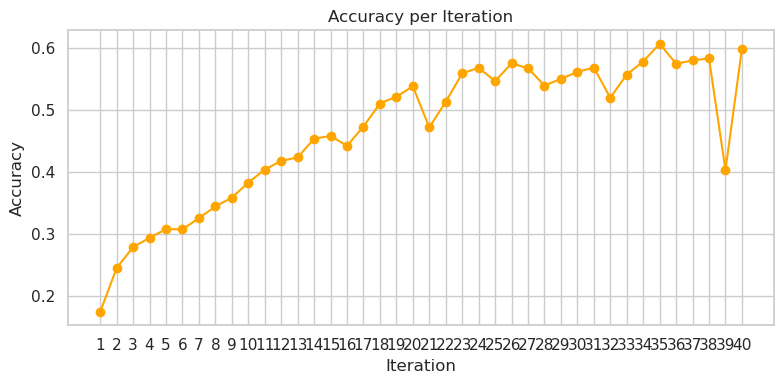

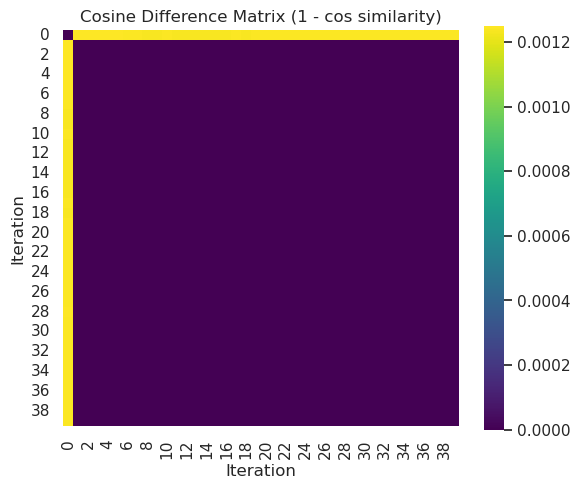

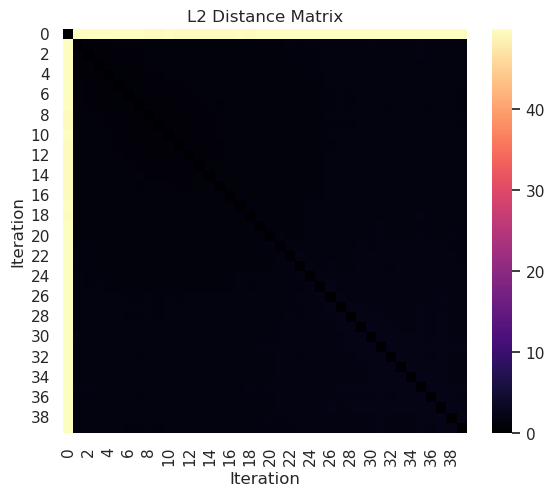

In [ ]:
# Ensure seaborn styling
sns.set(style="whitegrid")

# Plot 1: Bar plot of L2 norms
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(l2_norms) + 1), l2_norms, color='skyblue')
plt.xlabel("Iteration")
plt.ylabel("L2 Norm of Model Update")
plt.title("L2 Norms per Iteration")
plt.xticks(range(1, len(l2_norms) + 1))
plt.tight_layout()
plt.show()

# Plot 2: Line plot of Accuracy per Iteration
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, color='orange', marker='o')
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Accuracy per Iteration")
plt.xticks(range(1, len(accuracy_list) + 1))
plt.grid(True)  # Optional: adds grid lines for better readability
plt.tight_layout()
plt.show()


# Convert matrices to numpy
cos_diff_np = cos_diff_matrix.numpy()
l2_diff_np = l2_diff_matrix.numpy()

# Plot 3: Heatmap of cosine differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(cos_diff_np, annot=False, cmap="viridis", square=True)
plt.title("Cosine Difference Matrix (1 - cos similarity)")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()

# Plot 4: Heatmap of L2 differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(l2_diff_np, annot=False, cmap="magma", square=True)
plt.title("L2 Distance Matrix")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()



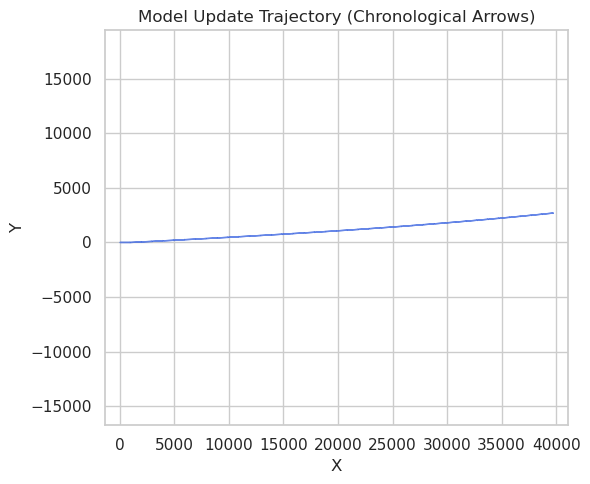

In [ ]:
# plot the trajectory of model updates in 2D space

# Step 1: Flatten updates (if not already done)
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 2: Get L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 3: Compute angles between successive updates
angles = [0.0]  # start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = F.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    # Determine rotation direction using sign of cross product
    sign = torch.sign(torch.dot(u_prev, u_curr))  # crude check
    if sign < 0:
        angle_diff = -angle_diff
    angles.append(angle_diff)

# Step 4: Convert to absolute angles
absolute_angles = [0.0]
for i in range(1, len(angles)):
    absolute_angles.append(absolute_angles[-1] + angles[i])

# Step 5: Compute vector endpoints
x, y = [0], [0]
for i in range(len(l2_norms)):
    dx = l2_norms[i] * np.cos(absolute_angles[i])
    dy = l2_norms[i] * np.sin(absolute_angles[i])
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)

# Step 6: Plot
plt.figure(figsize=(6, 5))
for i in range(len(l2_norms)):
    plt.arrow(x[i], y[i], x[i+1]-x[i], y[i+1]-y[i],
              head_width=0.05*max(l2_norms), length_includes_head=True,
              color='royalblue', alpha=0.8)

plt.title("Model Update Trajectory (Chronological Arrows)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


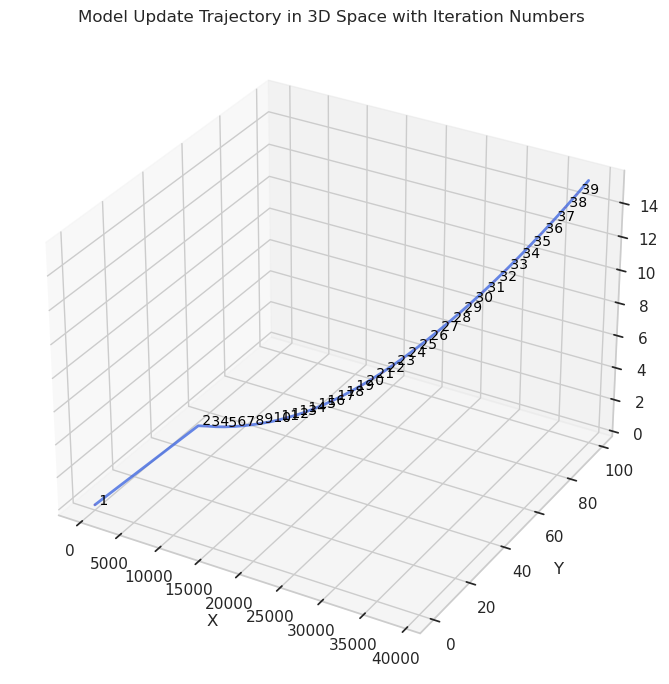

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.mplot3d import Axes3D

# Assuming model_updates is a dictionary or list with flattened model updates
# You would replace the below code with your actual model update data.
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]  # Flatten updates

# Calculate L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Compute angles between consecutive updates (using cosine similarity)
angles = [0.0]  # Start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = torch.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    angles.append(angle_diff)

# Compute 3D coordinates of the trajectory
x, y, z = [0], [0], [0]

# For simplicity, assume updates occur in 3D space
for i in range(1, len(l2_norms)):
    dx = l2_norms[i] * np.cos(angles[i])  # X direction
    dy = l2_norms[i] * np.sin(angles[i])  # Y direction
    dz = i * 0.02  # Slightly separate updates in the Z direction for clarity
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)
    z.append(z[-1] + dz)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D trajectory path as a line
ax.plot(x, y, z, color='royalblue', alpha=0.8, linewidth=2)

# Plot arrows for each update
for i in range(len(l2_norms) - 1):
    ax.quiver(x[i], y[i], z[i], x[i+1] - x[i], y[i+1] - y[i], z[i+1] - z[i],
              length=0.1, normalize=True, color='red', alpha=0.6)

    # Add iteration number as a label near the arrows
    ax.text(x[i] + 0.02, y[i] + 0.02, z[i] + 0.02, f" {i+1}", color='black', fontsize=10)

# Labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title("Model Update Trajectory in 3D Space with Iteration Numbers")

# Display the plot
plt.tight_layout()
plt.show()


# Attack with budget on L2 norm


In [ ]:
# copy the trained model0 to modelt
modelt.load_state_dict(model0.state_dict())

# test the modelt
test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(modelt, c_criterion1, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
print(f"modelt accuracy:{accuracy}")

modelt accuracy:0.5987


Average L2 Norm: 996.1488372802735
NaN detected in full_epoch_dir. Reducing learning rate to 1.0e-04 and retrying...
   1 batches | Sim: 0.9997 | L2: 3.1632 | Acc: 0.5981
   2 batches | Sim: 0.9998 | L2: 6.3255 | Acc: 0.5979
   4 batches | Sim: 0.9999 | L2: 12.6501 | Acc: 0.5958
   8 batches | Sim: 1.0000 | L2: 25.2993 | Acc: 0.5959
  16 batches | Sim: 1.0000 | L2: 50.5972 | Acc: 0.5971
  32 batches | Sim: 1.0000 | L2: 101.1936 | Acc: 0.5281
  64 batches | Sim: 1.0000 | L2: 202.3912 | Acc: 0.2065
 100 batches | Sim: 1.0000 | L2: 316.2359 | Acc: 0.1329
 120 batches | Sim: 1.0000 | L2: 379.4837 | Acc: 0.0585
 140 batches | Sim: 1.0000 | L2: 442.7290 | Acc: 0.0370
 200 batches | Sim: 1.0000 | L2: 632.4668 | Acc: 0.0272
 250 batches | Sim: 1.0000 | L2: 790.5789 | Acc: 0.0243
 300 batches | Sim: 1.0000 | L2: 948.6926 | Acc: 0.0220
 315 batches (full) | Sim: 1.0000 | L2: 996.1268 | Acc: 0.0197


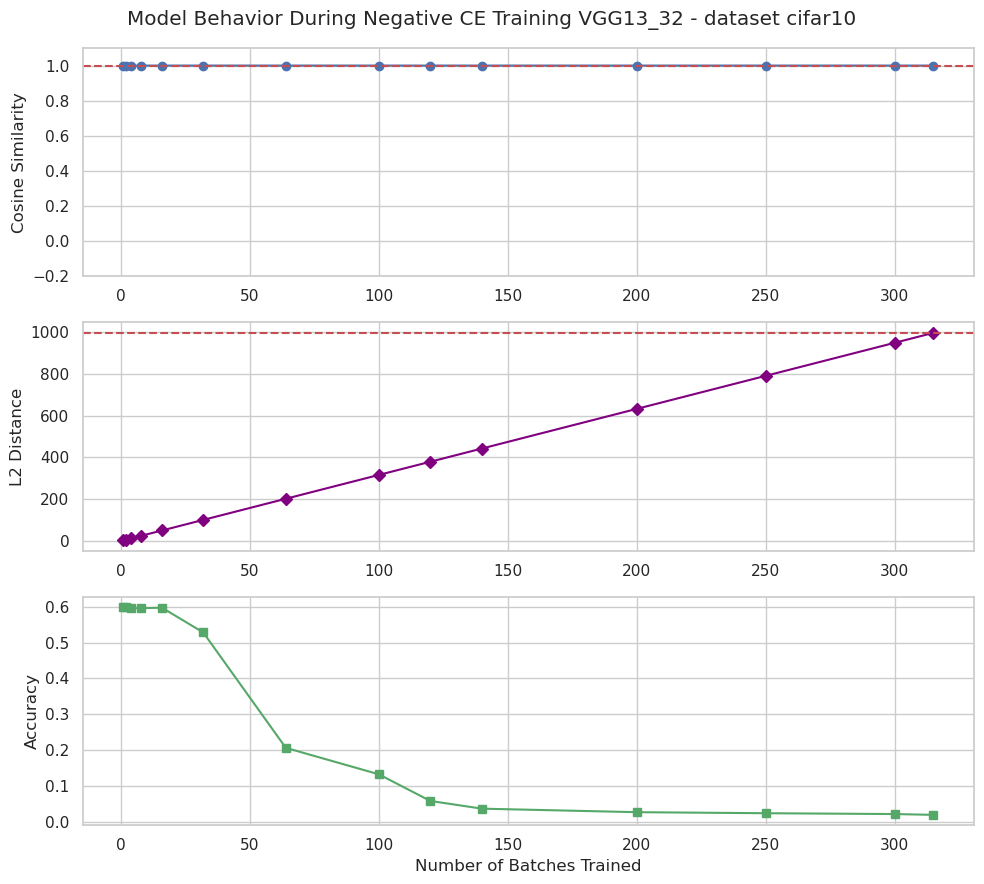

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms


# Assuming `modelt` is your pre-trained model on Fashion-MNIST
# Assuming `train_loader` and `val_loader` are DataLoaders for your training and validation data

class NegativeCrossEntropyLoss(nn.Module):
    def __init__(self):
        super(NegativeCrossEntropyLoss, self).__init__()
        self.ce_loss = nn.CrossEntropyLoss()

    def forward(self, outputs, labels):
        return -self.ce_loss(outputs, labels)

def train_with_negative_ce(model, data_loader, learning_rate, device, num_batches=None):
    """
    Train model with negative CE loss and always return:
    1. Parameter difference G_m
    2. Flattened gradient direction (normalized)
    3. Attacked model state dict
    """
    model.train()
    neg_ce_loss = NegativeCrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=learning_rate)
    
    # Save original model parameters
    original_state = deepcopy(model.state_dict())
    
    # Train loop
    batch_count = 0
    for inputs, labels in data_loader:
        if num_batches is not None and batch_count >= num_batches:
            break
            
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = neg_ce_loss(outputs, labels)
        loss.backward()
        optimizer.step()
        batch_count += 1
    
    # Get final model parameters
    attacked_state = deepcopy(model.state_dict())
    
    # Calculate parameter difference
    G_m = {name: attacked_state[name] - original_state[name] 
           for name in attacked_state}
    
    # Restore original parameters (optional but recommended)
    model.load_state_dict(original_state)
    
    # Flatten and normalize direction
    flat_gm = flatten_model(G_m)
    normalized_dir = flat_gm / torch.norm(flat_gm)
    
    return G_m, normalized_dir, attacked_state

def calculate_average_l2_norm(l2_norms):
    return sum(l2_norms) / len(l2_norms)

def calculate_l2_distance(original_weights, attacked_weights):
    """Calculate the L2 distance between two sets of weights."""
    return torch.norm(attacked_weights - original_weights).item()

def apply_attack(model, G_m, average_l2_norm, magnitudes):
    # Calculate the L2 norm of G_m
    total_norm = torch.sqrt(sum((G_m.norm() ** 2 for G_m in G_m.values())))
    
    # Normalize G_m by the average L2 norm
    normalized_G_m = {name: G_m * (average_l2_norm / total_norm) for name, G_m in G_m.items()}
    l2_distances = []
    attacked_models = []
    for magnitude in magnitudes:
        new_model = deepcopy(model)
        for name, param in new_model.named_parameters():
            param.data += magnitude * normalized_G_m[name]
        attacked_models.append(new_model)
        l2_distance = calculate_l2_distance(flatten_update(model.state_dict()), flatten_update(new_model.state_dict()))
        l2_distances.append(l2_distance)
    return attacked_models, l2_distances

def evaluate_model(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

def flatten_model(state_dict):
    """Flatten a model's state_dict into a single 1D tensor."""
    return torch.cat([param.flatten() for param in state_dict.values()])

def cosine_similarity(vec1, vec2):
    """Compute cosine similarity between two vectors"""
    return torch.dot(vec1, vec2) / (torch.norm(vec1) * torch.norm(vec2))

def calculate_l2_distance(state_dict1, state_dict2):
    """Compute L2 distance between two model state dicts"""
    total_distance = 0.0
    for key in state_dict1:
        total_distance += torch.sum((state_dict1[key] - state_dict2[key])**2)
    return torch.sqrt(total_distance).item()

def run_direction_experiment(model0, train_loader, test_data, device, 
                           batch_steps=[1, 2, 4, 8, 16, 'full']):
    """
    Compare directions, L2 distance, and validation accuracy using model0.
    Returns:
    - Cosine similarity trends
    - L2 distance from original model
    - Accuracy trends
    """
    results = {
        'cosine_sim': [],
        'l2_distance': [],  # New: tracks L2 distance from original model
        'accuracy': [],
        'num_batches': []
    }

    # Compute full epoch reference
    temp_model = deepcopy(model0)
    # Try reducing learning rate if NaNs appear in full_epoch_dir
    retries = 0
    temp_lr = learning_rate
    while retries < 5:
        temp_model = deepcopy(model0)
        _, full_epoch_dir, attacked_sd = train_with_negative_ce(temp_model, train_loader, temp_lr, device)
        
        if torch.isnan(full_epoch_dir).any() or torch.norm(full_epoch_dir) == 0:
            retries += 1
            temp_lr = temp_lr / 10
            print(f"NaN detected in full_epoch_dir. Reducing learning rate to {temp_lr:.1e} and retrying...")
        else:
            break
    else:
        raise ValueError("Could not fix NaNs in full_epoch_dir even after reducing learning rate.")

    attacked_model = deepcopy(model0)
    attacked_model.load_state_dict(attacked_sd)
    _, acc_full, _, _ = fl_validation(attacked_model, c_criterion1, test_data,
                                    server_batch_size=32, class_num=10,
                                    attack_method='none', mali_labels=[0,7],
                                    device=device)
    
    # Calculate L2 for full epoch
    l2_full = calculate_l2_distance(model0.state_dict(), attacked_sd)
    del temp_model, attacked_model

    for num_batches in batch_steps:
        temp_model = deepcopy(model0)
        
        if num_batches == 'full':
            results['num_batches'].append(len(train_loader))
            results['cosine_sim'].append(1.0)
            results['l2_distance'].append(l2_full)
            results['accuracy'].append(acc_full)
            print(f"{len(train_loader):>4} batches (full) | Sim: 1.0000 | L2: {l2_full:.4f} | Acc: {acc_full:.4f}")
            continue
            
        _, partial_dir, attacked_sd = train_with_negative_ce(temp_model, train_loader,
                                                             temp_lr, device, 
                                                            num_batches=num_batches)
        
        # Calculate metrics
        sim = cosine_similarity(full_epoch_dir, partial_dir).item()
        l2_dist = calculate_l2_distance(model0.state_dict(), attacked_sd)
        
        attacked_model = deepcopy(model0)
        attacked_model.load_state_dict(attacked_sd)
        _, acc, _, _ = fl_validation(attacked_model, c_criterion1, test_data,
                                   server_batch_size=32, class_num=10,
                                   attack_method='none', mali_labels=[0,7],
                                   device=device)
        
        # Store results
        results['num_batches'].append(num_batches)
        results['cosine_sim'].append(sim)
        results['l2_distance'].append(l2_dist)
        results['accuracy'].append(acc)
        # print("Full Epoch Direction Norm:", torch.norm(full_epoch_dir))
        # print("Any NaNs in full_epoch_dir?", torch.isnan(full_epoch_dir).any())

        print(f"{num_batches:>4} batches | Sim: {sim:.4f} | L2: {l2_dist:.4f} | Acc: {acc:.4f}")
        del temp_model, attacked_model

    return results

def plot_results(results, average_l2_norm):
    """Plot cosine similarity, L2 distance, and accuracy trends"""
    import matplotlib.pyplot as plt
    
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9))
    
    # Plot cosine similarity
    ax1.plot(results['num_batches'], results['cosine_sim'], 'o-', color='b')
    ax1.set_ylabel('Cosine Similarity')
    ax1.set_ylim(-0.2, 1.1)
    ax1.axhline(y=1.0, color='r', linestyle='--')
    ax1.grid(True)
    
    # Plot L2 distance
    ax2.plot(results['num_batches'], results['l2_distance'], 'D-', color='purple')
    ax2.set_ylabel('L2 Distance')
    ax2.axhline(y=average_l2_norm, color='r', linestyle='--')
    ax2.grid(True)
    
    # Plot accuracy
    ax3.plot(results['num_batches'], results['accuracy'], 's-', color='g')
    ax3.set_xlabel('Number of Batches Trained')
    ax3.set_ylabel('Accuracy')
    ax3.grid(True)
    
    plt.suptitle(f"Model Behavior During Negative CE Training {model_name} - dataset {dataset}")
    plt.tight_layout()
    plt.show()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Assuming `l2_norms` is the list of L2 norms recorded during benign training
average_l2_norm = calculate_average_l2_norm(l2_norms)
print(f"Average L2 Norm: {average_l2_norm}")

results = run_direction_experiment(model0=modelt, 
                                    train_loader=train_loader, 
                                    device=device, 
                                    test_data=test_data,
                                    batch_steps=[1, 2, 4, 8, 16, 32, 64, 100, 120, 140, 200, 250, 300, "full"])


plot_results(results, average_l2_norm)